# Physics-Informed Neural Networks (PINN) for Mechanics

**Mini-project implementation based on:** *Data Driven Solutions and Discoveries in Mechanics Using Physics Informed Neural Network*.

This final notebook implements the three experiments presented in the paper:

1. **1D consolidation** — a time-dependent diffusion PDE with an analytical reference solution.
2. **2D steady-state heat conduction** — a Poisson equation solved with a PINN.
3. **Inverse structural dynamics** — identification of damping `c` and stiffness `k` in a damped single-degree-of-freedom system.

### Run settings
- **Default: `RUN_MODE = "validation"`**. This is intentionally lightweight so **Run All finishes locally on a normal CPU**.
- **Optional: `RUN_MODE = "paper"`**. This switches to the point counts, architectures, learning rates, epoch counts, and optimizer schedules reported in the paper and can take a long time.
- The notebook therefore provides a practical demonstration mode without claiming that the reduced run is an exact numerical reproduction of the paper.

The paper formulates the PINN objective as `L = wf Lf + wb Lb + wd Ld`, where the terms represent physics-residual, boundary/initial-condition, and data mismatch losses. Automatic differentiation is used to compute the required derivatives.

Run the cells from top to bottom.


In [1]:
# Dependencies and global configuration
# In a fresh environment: pip install torch numpy matplotlib scipy

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from math import pi

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Use "validation" for a quick, reliable demonstration.
# Use "paper" to run with the hyperparameters reported in the paper.
RUN_MODE = "validation"


Device: cpu


## 1. PINN formulation

A neural network approximates the unknown physical field, while automatic differentiation allows the governing differential equation to be evaluated directly at collocation points.

For inverse problems, unknown physical parameters are optimized together with the network parameters.


In [2]:
class PINN(nn.Module):
    def __init__(self, input_dim, output_dim=1, hidden_layers=4, hidden_units=50, init="xavier_uniform"):
        super().__init__()
        layers = [nn.Linear(input_dim, hidden_units), nn.Tanh()]
        for _ in range(hidden_layers - 1):
            layers += [nn.Linear(hidden_units, hidden_units), nn.Tanh()]
        layers += [nn.Linear(hidden_units, output_dim)]
        self.net = nn.Sequential(*layers)

        # Xavier/Glorot-style initialization
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight) if init == "xavier_normal" else nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.net(x)


def grad(y, x):
    return torch.autograd.grad(
        y, x,
        grad_outputs=torch.ones_like(y),
        create_graph=True,
        retain_graph=True
    )[0]


def mse(x):
    return torch.mean(x**2)


def train_model(model, loss_fn, optimizer, epochs=2000, print_every=250):
    history = []
    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()
        loss = loss_fn()
        loss.backward()
        optimizer.step()

        history.append(float(loss.detach().cpu()))

        if epoch == 1 or epoch % print_every == 0:
            print(f"Epoch {epoch:6d} | loss = {history[-1]:.6e}")

    return history


def train_lbfgs(model, loss_fn, max_iter=500, history=None):
    if history is None: history=[]
    optimizer = torch.optim.LBFGS(list(model.parameters()), lr=1.0, max_iter=max_iter, max_eval=max_iter, tolerance_grad=1e-7, tolerance_change=1e-9, history_size=50, line_search_fn="strong_wolfe")
    calls={"n":0}
    def closure():
        optimizer.zero_grad(); loss=loss_fn(); loss.backward(); history.append(float(loss.detach().cpu())); calls["n"]+=1; return loss
    optimizer.step(closure)
    print("L-BFGS closure evaluations:", calls["n"])
    return history


In [3]:
# Configuration: paper mode reproduces the reported settings; validation mode is intentionally reduced.
if RUN_MODE == "paper":
    TMAX=0.5; N_F=500; N_BX=250; N_BT=125; EPOCHS=50000; LR=1e-3; USE_LBFGS=True
else:
    TMAX=0.5; N_F=200; N_BX=80; N_BT=40; EPOCHS=200; LR=1e-3; USE_LBFGS=False

x_f=torch.rand(N_F,1,device=device); t_f=torch.rand(N_F,1,device=device)*TMAX
X_f=torch.cat([x_f,t_f],1).requires_grad_(True)
t_x0=torch.rand(N_BX//2,1,device=device)*TMAX; t_x1=torch.rand(N_BX-N_BX//2,1,device=device)*TMAX
X_x0=torch.cat([torch.zeros_like(t_x0),t_x0],1)
X_x1=torch.cat([torch.ones_like(t_x1),t_x1],1).requires_grad_(True)
x_t0=torch.rand(N_BT,1,device=device); X_t0=torch.cat([x_t0,torch.zeros_like(x_t0)],1)

model1=PINN(2,hidden_layers=5,hidden_units=50,init="xavier_normal").to(device)
optimizer1=torch.optim.Adam(model1.parameters(),lr=LR)

def consolidation_output(X): return X[:,:1]*model1(X)

def loss_consolidation():
    p=consolidation_output(X_f); dp=grad(p,X_f); r_f=dp[:,1:2]-grad(dp[:,0:1],X_f)[:,0:1]
    r_x0=consolidation_output(X_x0); r_x1=grad(consolidation_output(X_x1),X_x1)[:,0:1]
    r_t0=consolidation_output(X_t0)-1.0
    r_b=torch.cat([r_x0,r_x1,r_t0],0)
    return 0.25*mse(r_f)+0.25*mse(r_b)

history1 = train_model(model1, loss_consolidation, optimizer1, epochs=EPOCHS, print_every=max(1,EPOCHS//5))
if USE_LBFGS:
    history1 = train_lbfgs(model1, loss_consolidation, max_iter=500, history=history1)


Epoch      1 | loss = 1.049081e-01
Epoch     40 | loss = 3.771437e-02
Epoch     80 | loss = 2.331220e-02
Epoch    120 | loss = 1.906560e-02
Epoch    160 | loss = 1.653576e-02
Epoch    200 | loss = 1.492003e-02


Maximum absolute error: 0.9098458924625861
Mean squared error: 0.005721468318638625


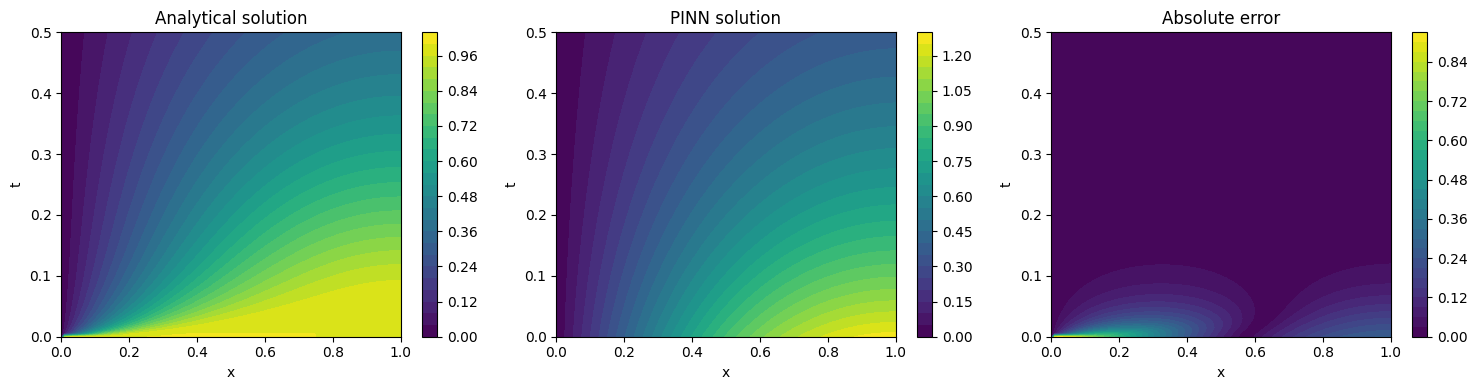

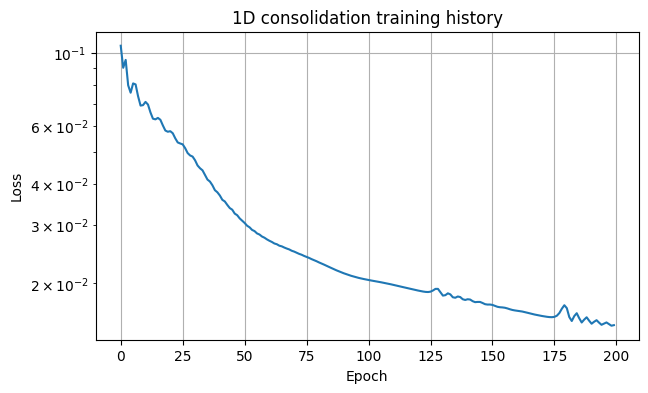

In [4]:
# Analytical solution from the paper:
# p_hat = sum over odd m of (4/(m*pi)) sin(m*pi*x/2) exp(-m^2*pi^2*t/4)

def consolidation_exact(x, t, n_terms=200):
    x = np.asarray(x)
    t = np.asarray(t)
    out = np.zeros(np.broadcast(x, t).shape)
    for m in range(1, 2*n_terms, 2):
        out += (4/(m*pi)) * np.sin(m*pi*x/2) * np.exp(-m*m*pi*pi*t/4)
    return out

# Test on a regular grid
nx = 100; nt = 100
xg = np.linspace(0, 1, nx)
tg = np.linspace(0, TMAX, nt)
XX, TT = np.meshgrid(xg, tg)
X_test = torch.tensor(
    np.column_stack([XX.ravel(), TT.ravel()]),
    dtype=torch.float32, device=device
)

with torch.no_grad():
    P_pred = consolidation_output(X_test).cpu().numpy().reshape(nt, nx)

P_exact = consolidation_exact(XX, TT)
abs_error = np.abs(P_pred - P_exact)

print("Maximum absolute error:", abs_error.max())
print("Mean squared error:", np.mean((P_pred - P_exact)**2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, data, title in zip(
    axes,
    [P_exact, P_pred, abs_error],
    ["Analytical solution", "PINN solution", "Absolute error"]
):
    im = ax.contourf(XX, TT, data, levels=30)
    ax.set_xlabel("x")
    ax.set_ylabel("t")
    ax.set_title(title)
    plt.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.semilogy(history1)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("1D consolidation training history")
plt.grid(True)
plt.show()


In [5]:
# Demo configuration
if RUN_MODE == "paper":
    N_F2=1500; N_B2=500; EPOCHS2=50000; LR2=5e-4; USE_LBFGS2=True
else:
    N_F2=200; N_B2=100; EPOCHS2=200; LR2=5e-4; USE_LBFGS2=False

# Interior points
x = -1 + 2*torch.rand(N_F2, 1, device=device)
y = -1 + 2*torch.rand(N_F2, 1, device=device)
X_f2 = torch.cat([x, y], dim=1).requires_grad_(True)

# Boundary points on all four edges
n_side = N_B2 // 4
s = -1 + 2*torch.rand(n_side, 1, device=device)

X_b2 = torch.cat([
    torch.cat([s, -torch.ones_like(s)], dim=1),
    torch.cat([s,  torch.ones_like(s)], dim=1),
    torch.cat([-torch.ones_like(s), s], dim=1),
    torch.cat([ torch.ones_like(s), s], dim=1),
], dim=0)

model2 = PINN(input_dim=2, hidden_layers=4, hidden_units=50, init="xavier_uniform").to(device)
optimizer2 = torch.optim.Adam(model2.parameters(), lr=LR2)

def loss_heat():
    T = model2(X_f2)
    dT = grad(T, X_f2)
    T_x = dT[:, 0:1]
    T_y = dT[:, 1:2]

    T_xx = grad(T_x, X_f2)[:, 0:1]
    T_yy = grad(T_y, X_f2)[:, 1:2]

    r_f = T_xx + T_yy + 1.0

    T_b = model2(X_b2)
    r_b = T_b  # T=0 on boundary

    # Paper uses wf = wb = 1/2.
    return 0.5*mse(r_f) + 0.5*mse(r_b)

history2 = train_model(
    model2, loss_heat, optimizer2,
    epochs=EPOCHS2, print_every=max(1,EPOCHS2//5)
)
if USE_LBFGS2:
    history2 = train_lbfgs(model2, loss_heat, max_iter=500, history=history2)


Epoch      1 | loss = 5.331876e-01
Epoch     40 | loss = 2.615627e-01
Epoch     80 | loss = 9.162306e-02
Epoch    120 | loss = 3.412479e-02
Epoch    160 | loss = 1.574892e-02
Epoch    200 | loss = 7.621570e-03


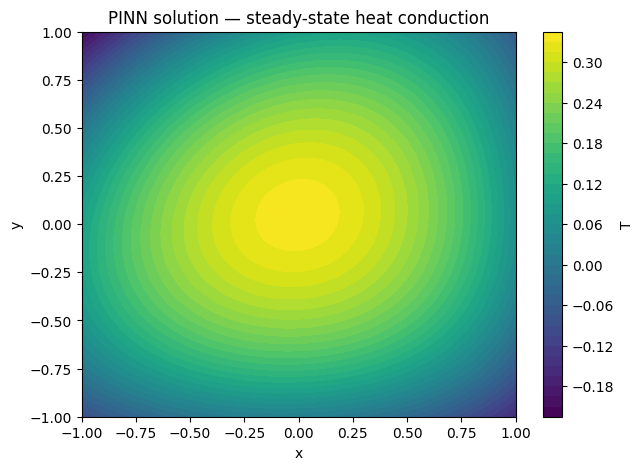

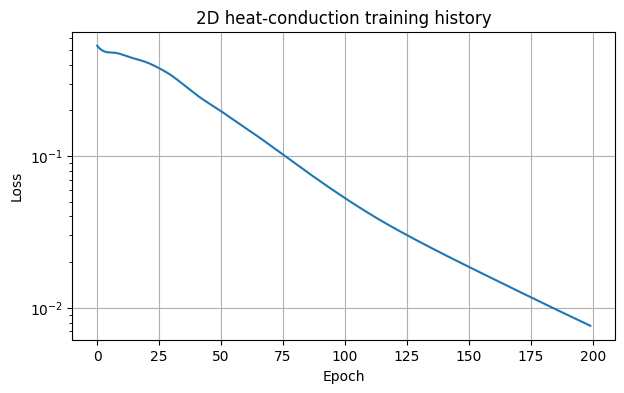

Boundary prediction max |T|: 0.1647839
Test-grid mean squared PDE residual: 0.013626816682517529
Boundary max absolute error: 0.16478389501571655


In [6]:
# Visualize the PINN heat solution
nplot = 100
xv = np.linspace(-1, 1, nplot)
yv = np.linspace(-1, 1, nplot)
XG, YG = np.meshgrid(xv, yv)

X_heat_test = torch.tensor(
    np.column_stack([XG.ravel(), YG.ravel()]),
    dtype=torch.float32, device=device
)

with torch.no_grad():
    T_pred = model2(X_heat_test).cpu().numpy().reshape(nplot, nplot)

plt.figure(figsize=(7, 5))
plt.contourf(XG, YG, T_pred, levels=40)
plt.colorbar(label="T")
plt.xlabel("x")
plt.ylabel("y")
plt.title("PINN solution — steady-state heat conduction")
plt.show()

plt.figure(figsize=(7, 4))
plt.semilogy(history2)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("2D heat-conduction training history")
plt.grid(True)
plt.show()

print("Boundary prediction max |T|:",
      np.max(np.abs(model2(X_b2).detach().cpu().numpy())))


# Additional numerical checks on the trained PINN.
# Use a smaller diagnostic grid for the derivative-based residual check so the local demo stays fast.
metric_n = 40
xm = np.linspace(-1, 1, metric_n)
ym = np.linspace(-1, 1, metric_n)
XM, YM = np.meshgrid(xm, ym)
X_heat_metric = torch.tensor(np.column_stack([XM.ravel(), YM.ravel()]), dtype=torch.float32, device=device)
X_heat_test_req = X_heat_metric.clone().detach().requires_grad_(True)
T_test = model2(X_heat_test_req)
dT_test = grad(T_test, X_heat_test_req)
T_x_test = dT_test[:, 0:1]
T_y_test = dT_test[:, 1:2]
T_xx_test = grad(T_x_test, X_heat_test_req)[:, 0:1]
T_yy_test = grad(T_y_test, X_heat_test_req)[:, 1:2]
pde_residual_test = T_xx_test + T_yy_test + 1.0
print("Test-grid mean squared PDE residual:", float(torch.mean(pde_residual_test**2).detach().cpu()))
print("Boundary max absolute error:", float(np.max(np.abs(model2(X_b2).detach().cpu().numpy()))))


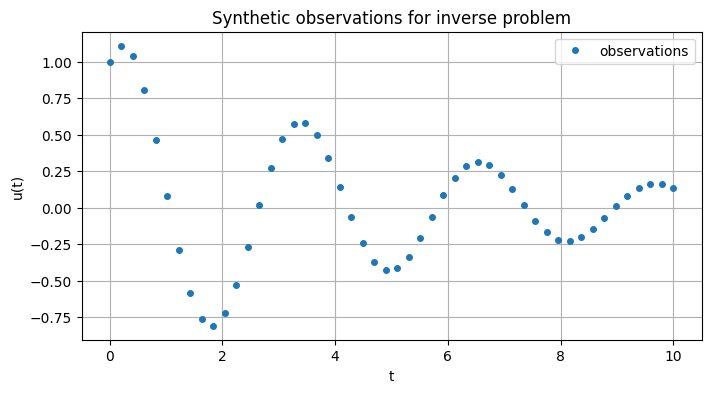

In [7]:
# True parameters used to generate synthetic observations
m_true = 1.0
c_true = 0.4
k_true = 4.0
u0 = 1.0
v0 = 1.0

def exact_sdof(t, m=1.0, c=0.4, k=4.0, u0=1.0, v0=1.0):
    wn = np.sqrt(k/m)
    xi = c / (2*m*wn)
    wd = wn * np.sqrt(1 - xi**2)

    return np.exp(-xi*wn*t) * (
        u0*np.cos(wd*t)
        + (v0 + xi*wn*u0)/wd * np.sin(wd*t)
    )

# The paper gives 50 equispaced observations but does not state the time interval in the extracted text.
T_FINAL = 10.0
# 50 observation points, as in the paper
t_data_np = np.linspace(0, T_FINAL, 50).reshape(-1, 1)
u_data_np = exact_sdof(
    t_data_np, m_true, c_true, k_true, u0, v0
)

t_data = torch.tensor(t_data_np, dtype=torch.float32, device=device)
u_data = torch.tensor(u_data_np, dtype=torch.float32, device=device)

plt.figure(figsize=(8, 4))
plt.plot(t_data_np, u_data_np, "o", ms=4, label="observations")
plt.xlabel("t")
plt.ylabel("u(t)")
plt.title("Synthetic observations for inverse problem")
plt.legend()
plt.grid(True)
plt.show()


In [8]:
# PINN for inverse identification
# The paper specifies 100 physics, 50 boundary, 50 observation, 10000 test points and 100000 Adam epochs.
# The observation time interval is not stated in the extracted paper text; we use [0,10] explicitly.
T_FINAL = 10.0
if RUN_MODE == "paper":
    N_F3=100; N_B3=50; EPOCHS3=100000; LR3=5e-4
else:
    N_F3=80; N_B3=50; EPOCHS3=300; LR3=5e-4

# Random physics points
t_f3 = (T_FINAL * torch.rand(N_F3, 1, device=device)).requires_grad_(True)

# Trainable physical parameters
# The paper describes c and k themselves as trainable unknown parameters; no reparameterization is specified.
# We therefore optimize c and k directly. Initial values are implementation choices because the paper does not report them.
c_param = nn.Parameter(torch.tensor(1.0, device=device))
k_param = nn.Parameter(torch.tensor(1.0, device=device))

model3 = PINN(input_dim=1, hidden_layers=3, hidden_units=32, init="xavier_uniform").to(device)

optimizer3 = torch.optim.Adam(
    list(model3.parameters()) + [c_param, k_param],
    lr=LR3
)

def loss_inverse():
    t = t_f3
    u = model3(t)

    du = grad(u, t)
    d2u = grad(du, t)

    c = c_param
    k = k_param

    # m*u_tt + c*u_t + k*u = 0
    r_f = d2u + c*du + k*u

    # Initial conditions
    t0 = torch.zeros(1, 1, device=device, requires_grad=True)
    u0_pred = model3(t0)
    du0_pred = grad(u0_pred, t0)

    r_ic_u = u0_pred - u0
    r_ic_v = du0_pred - v0

    # Observation/data mismatch
    u_obs_pred = model3(t_data)
    r_data = u_obs_pred - u_data

    # Equal weighting of physics, boundary/initial conditions and data.
    r_b = torch.cat([r_ic_u, r_ic_v], dim=0)
    return 0.25*mse(r_f) + 0.25*mse(r_b) + 0.25*mse(r_data)

history3 = []
c_history = []
k_history = []

for epoch in range(1, EPOCHS3 + 1):
    optimizer3.zero_grad()
    loss = loss_inverse()
    loss.backward()
    optimizer3.step()

    history3.append(float(loss.detach().cpu()))
    c_history.append(float(c_param.detach().cpu()))
    k_history.append(float(k_param.detach().cpu()))

    if epoch == 1 or epoch % 500 == 0:
        print(
            f"Epoch {epoch:6d} | loss={history3[-1]:.6e} | "
            f"c={c_history[-1]:.6f} | k={k_history[-1]:.6f}"
        )


Epoch      1 | loss=2.966166e-01 | c=0.999500 | k=0.999500


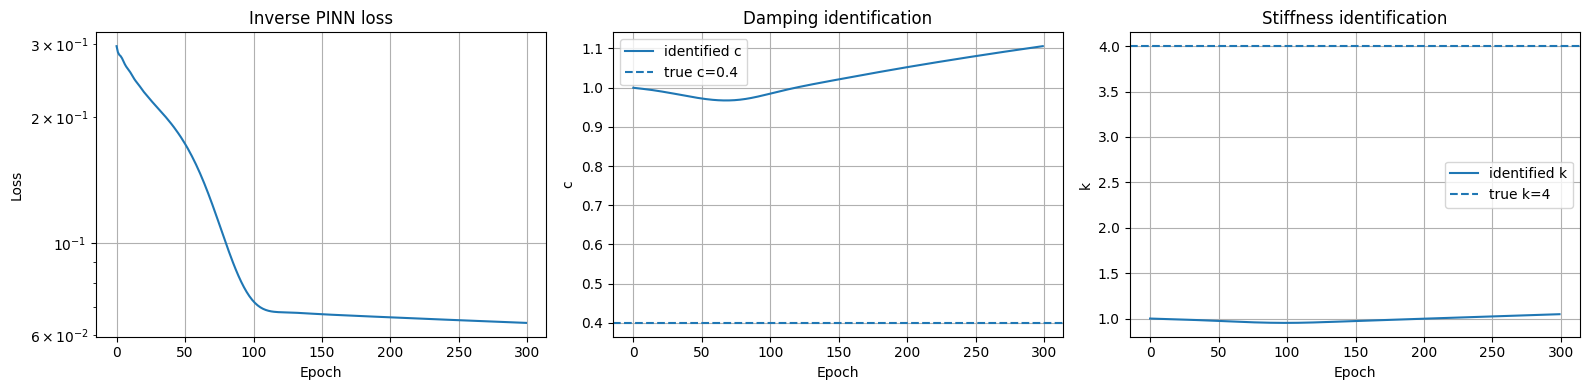

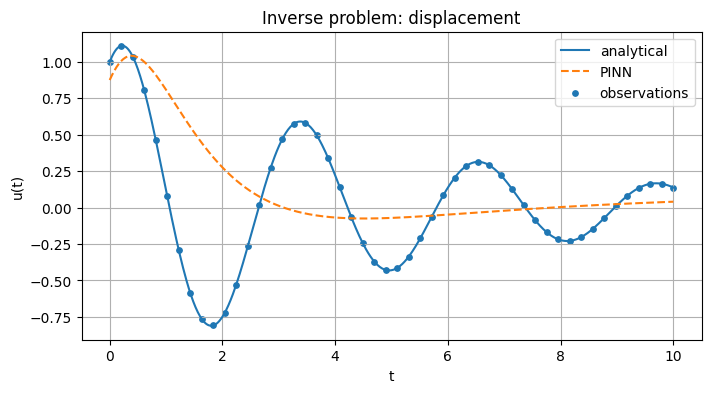

True c = 0.400000, identified c = 1.105580
True k = 4.000000, identified k = 1.047393


In [9]:
# Plot identified parameters and displacement
t_plot = np.linspace(0, T_FINAL, 500).reshape(-1, 1)
t_plot_t = torch.tensor(t_plot, dtype=torch.float32, device=device)

with torch.no_grad():
    u_pred3 = model3(t_plot_t).cpu().numpy().ravel()

c_est = c_history[-1]
k_est = k_history[-1]
u_exact3 = exact_sdof(t_plot, m_true, c_true, k_true, u0, v0).ravel()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(history3)
axes[0].set_yscale("log")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Inverse PINN loss")
axes[0].grid(True)

axes[1].plot(c_history, label="identified c")
axes[1].axhline(c_true, linestyle="--", label="true c=0.4")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("c")
axes[1].set_title("Damping identification")
axes[1].legend()
axes[1].grid(True)

axes[2].plot(k_history, label="identified k")
axes[2].axhline(k_true, linestyle="--", label="true k=4")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("k")
axes[2].set_title("Stiffness identification")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(t_plot, u_exact3, label="analytical")
plt.plot(t_plot, u_pred3, "--", label="PINN")
plt.scatter(t_data_np, u_data_np, s=15, label="observations")
plt.xlabel("t")
plt.ylabel("u(t)")
plt.title("Inverse problem: displacement")
plt.legend()
plt.grid(True)
plt.show()

print(f"True c = {c_true:.6f}, identified c = {c_est:.6f}")
print(f"True k = {k_true:.6f}, identified k = {k_est:.6f}")


# Conclusion and paper-alignment notes

This notebook demonstrates the central idea of the paper: a neural network approximates a physical solution while its training objective enforces governing differential equations and boundary/initial conditions. The inverse example additionally treats unknown physical parameters as trainable quantities.

### Default local validation mode
The default `RUN_MODE = "validation"` uses reduced collocation-point counts and training epochs so the complete notebook can be executed locally with **Run All** on a typical CPU. These settings are for demonstration/validation and are not claimed to reproduce the paper's final numerical accuracy.

### Paper mode
`RUN_MODE = "paper"` retains the paper-aligned architectures, point counts, learning rates, epoch counts, and L-BFGS stages described in the implementation. This mode is computationally expensive and is optional rather than the default.

### Reproducibility note
The paper specifies 50 equispaced observations for Experiment 3 but the extracted paper text does not state their time interval. This implementation explicitly uses `[0, 10]` as an implementation choice.


## Final result summary

The default run prints:
- Experiment 1 maximum absolute error and MSE against the analytical solution.
- Experiment 2 test-grid mean squared PDE residual and boundary error.
- Experiment 3 identified damping `c` and stiffness `k`.

